
# Metamer-SAE — Notebook 02
## Stimulus Collection and Pairing

**Milestone 1 · Colab prototype · Phase 2**

### Research objective

This notebook retrieves, validates and organizes existing visual stimuli from Feather et al. (2023).

The initial experiment compares three matched image conditions:

1. Natural source photographs.
2. Standard ResNet50 metamers.
3. Adversarial ResNet50 metamers.

Each experimental unit is a complete triplet belonging to the same source-image index and generation layer.

### Experimental configuration

| Parameter | Configuration |
|---|---|
| Standard experiment | experiment_1 |
| Standard network | resnet50 |
| Adversarial experiment | experiment_3 |
| Adversarial network | resnet50_l2_3_robust |
| Generation layer | layer2_fake_relu |
| Random seed | 42 |
| Target triplets | 48 |

### Dataset allocation

- Development: 8 triplets.
- Primary evaluation: 32 triplets.
- Reserve: 8 triplets.

Image index 0 is reserved for development.

### Important methodological rules

- Only complete source/standard/adversarial triplets are retained.
- Missing images are recorded, not silently replaced.
- All three conditions must use the same source-image index and generation layer.
- Feather stimuli are held-out evaluation data.
- No PCA or SAE training takes place in this notebook.
- No human behavioural or audio data are accessed.

### Expected outputs

- Three organized stimulus subsets.
- A complete CSV manifest.
- A retrieval failures report.
- A sampling summary JSON.
- Three visual galleries.
- A validation report.


In [ ]:

# ============================================================
# 1. ENVIRONMENT AND STORAGE SETUP
# ============================================================

import os
import sys
import json
import random
import hashlib
import subprocess
import importlib.util

from pathlib import Path
from datetime import datetime, timezone

# Reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)

# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Permanent project directory
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/metamer-sae"
)

# Main stimulus directory
STIMULI_DIR = PROJECT_ROOT / "stimuli"

# Three experimental subsets
SUBSETS = [
    "development",
    "primary_evaluation",
    "reserve"
]

# Three image conditions
CONDITIONS = [
    "source",
    "standard_resnet50",
    "adversarial_resnet50"
]

# Create directory structure
for subset in SUBSETS:
    for condition in CONDITIONS:
        (
            STIMULI_DIR /
            subset /
            condition
        ).mkdir(parents=True, exist_ok=True)

# Supporting directories
MANIFEST_DIR = STIMULI_DIR / "manifests"
VISUALIZATION_DIR = STIMULI_DIR / "visualizations"

MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Temporary download/cache directory
CACHE_DIR = Path("/content/metamer_sae_phase2_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Record the experiment configuration
EXPERIMENT_CONFIG = {
    "standard_experiment": "experiment_1",
    "standard_network": "resnet50",
    "adversarial_experiment": "experiment_3",
    "adversarial_network": "resnet50_l2_3_robust",
    "generation_layer": "layer2_fake_relu",
    "random_seed": RANDOM_SEED,
    "target_triplets": 48,
    "development": 8,
    "primary_evaluation": 32,
    "reserve": 8
}

print("Google Drive mounted successfully.")
print()
print("Project directory:", PROJECT_ROOT)
print("Stimulus directory:", STIMULI_DIR)
print("Cache directory:", CACHE_DIR)
print()
print("Experimental configuration:")
print(json.dumps(EXPERIMENT_CONFIG, indent=4))

print("\nCreated directory structure:")
for path in sorted(STIMULI_DIR.rglob("*")):
    if path.is_dir():
        print("  ", path.relative_to(PROJECT_ROOT))


Mounted at /content/drive
Google Drive mounted successfully.

Project directory: /content/drive/MyDrive/metamer-sae
Stimulus directory: /content/drive/MyDrive/metamer-sae/stimuli
Cache directory: /content/metamer_sae_phase2_cache

Experimental configuration:
{
    "standard_experiment": "experiment_1",
    "standard_network": "resnet50",
    "adversarial_experiment": "experiment_3",
    "adversarial_network": "resnet50_l2_3_robust",
    "generation_layer": "layer2_fake_relu",
    "random_seed": 42,
    "target_triplets": 48,
    "development": 8,
    "primary_evaluation": 32,
    "reserve": 8
}

Created directory structure:
   stimuli/development
   stimuli/development/adversarial_resnet50
   stimuli/development/source
   stimuli/development/standard_resnet50
   stimuli/manifests
   stimuli/primary_evaluation
   stimuli/primary_evaluation/adversarial_resnet50
   stimuli/primary_evaluation/source
   stimuli/primary_evaluation/standard_resnet50
   stimuli/reserve
   stimuli/reserve/adver

## 2. Clone Feather's repository

The Feather repository is not a pip-installable package. This cell shallow-clones it if it is absent. If the folder already exists, it leaves your checkout untouched.

In [ ]:

FEATHER_REPO_URL = (
    "https://github.com/jenellefeather/model_metamers_pytorch.git"
)

FEATHER_REPO_DIR = Path("/content/model_metamers_pytorch")

# Exact commit recorded in the completed Notebook 01.
# We use this to keep Notebook 02 consistent with Notebook 01.
RECORDED_COMMIT = "d9629b58ad43ce9a6bd74be951869cffbd8e8161"

# Clone the repository if it is missing.
if not FEATHER_REPO_DIR.exists():

    print("Feather repository not found.")
    print("Cloning Feather's repository...")

    subprocess.run(
        [
            "git", "clone",
            FEATHER_REPO_URL,
            str(FEATHER_REPO_DIR)
        ],
        check=True
    )

elif not (FEATHER_REPO_DIR / ".git").exists():

    raise RuntimeError(
        f"The folder exists but is not a Git repository: "
        f"{FEATHER_REPO_DIR}"
    )

else:
    print("Existing Feather repository found.")

# Move to the exact commit used in Notebook 01.
print("\nChecking out the recorded Notebook 01 commit...")

subprocess.run(
    [
        "git", "-C", str(FEATHER_REPO_DIR),
        "checkout", "--detach", RECORDED_COMMIT
    ],
    check=True
)

# Verify the commit.
CURRENT_COMMIT = subprocess.check_output(
    [
        "git", "-C", str(FEATHER_REPO_DIR),
        "rev-parse", "HEAD"
    ],
    text=True
).strip()

print("\nRepository location:", FEATHER_REPO_DIR)
print("Recorded commit:", RECORDED_COMMIT)
print("Current commit:", CURRENT_COMMIT)

assert CURRENT_COMMIT == RECORDED_COMMIT, (
    "Repository commit does not match Notebook 01!"
)

print("\nSUCCESS: Feather repository restored.")
print("Notebook 02 is using the same repository version as Notebook 01.")


Feather repository not found.
Cloning Feather's repository...

Checking out the recorded Notebook 01 commit...

Repository location: /content/model_metamers_pytorch
Recorded commit: d9629b58ad43ce9a6bd74be951869cffbd8e8161
Current commit: d9629b58ad43ce9a6bd74be951869cffbd8e8161

SUCCESS: Feather repository restored.
Notebook 02 is using the same repository version as Notebook 01.



## 3. Load and verify Feather's visual experiment metadata

Before collecting images, we need to verify that the two selected
Feather experiments contain the intended models and that both
models support the same metamer-generation layer.

We will use Feather's existing metadata:

- `TURK_IMAGE_EXPERIMENTS_GROUPINGS`: identifies the visual experiment
  groups and their associated metadata.
- `ALL_NETWORKS_AND_LAYERS_IMAGES`: provides the available metamer
  display layers for each network.

Our selected conditions are:

| Condition | Experiment | Network |
|---|---|---|
| Standard | experiment_1 | resnet50 |
| Adversarial | experiment_3 | resnet50_l2_3_robust |

The generation layer selected for both conditions is:

`layer2_fake_relu`

This cell will:

1. Import Feather's metadata.
2. Retrieve the small experiment-parameter JSON files.
3. Verify that each selected network belongs to its intended experiment.
4. Verify that `layer2_fake_relu` is available for both networks.
5. Display a verification table.

**Important:** This cell retrieves experiment metadata only.
It does not download the stimulus images, model checkpoints,
or train any models.


In [ ]:
import importlib
import pandas as pd

from urllib.request import urlopen


# ------------------------------------------
# 1. Ensure required repository dependencies
# ------------------------------------------

for package in ["resampy", "tensorboardX", "cox"]:
    try:
        importlib.import_module(package)

    except ImportError:
        print(f"Installing missing dependency: {package}")

        subprocess.check_call([
            sys.executable, "-m", "pip",
            "install", "-q", package
        ])

        importlib.import_module(package)


# ------------------------------------------
# 2. Import Feather's metadata
# ------------------------------------------

if str(FEATHER_REPO_DIR) not in sys.path:
    sys.path.insert(0, str(FEATHER_REPO_DIR))

from model_analysis_folders import all_model_info

VISUAL_EXPERIMENTS = (
    all_model_info.TURK_IMAGE_EXPERIMENTS_GROUPINGS
)

NETWORK_LAYER_METADATA = (
    all_model_info.ALL_NETWORKS_AND_LAYERS_IMAGES
)

print("Successfully imported Feather's visual metadata.")

print(
    "Number of visual experiment groups:",
    len(VISUAL_EXPERIMENTS)
)

print(
    "Number of network layer catalogues:",
    len(NETWORK_LAYER_METADATA)
)


# ------------------------------------------
# 3. Define the selected conditions
# ------------------------------------------

SELECTED_CONDITIONS = [
    {
        "label": "Standard ResNet50",
        "experiment_key": EXPERIMENT_CONFIG["standard_experiment"],
        "network_key": EXPERIMENT_CONFIG["standard_network"]
    },
    {
        "label": "Adversarial ResNet50",
        "experiment_key": EXPERIMENT_CONFIG["adversarial_experiment"],
        "network_key": EXPERIMENT_CONFIG["adversarial_network"]
    }
]

GENERATION_LAYER = EXPERIMENT_CONFIG["generation_layer"]


# ------------------------------------------
# 4. Helper to read Feather's JSON metadata
# ------------------------------------------

def read_remote_json(url):

    with urlopen(url, timeout=40) as response:
        return json.loads(response.read().decode("utf-8"))


# ------------------------------------------
# 5. Verify experiments, networks and layers
# ------------------------------------------

verification_rows = []

for condition in SELECTED_CONDITIONS:

    experiment_key = condition["experiment_key"]
    network_key = condition["network_key"]

    print("\nInspecting:", condition["label"])

    # Check that the experiment exists.
    if experiment_key not in VISUAL_EXPERIMENTS:
        raise KeyError(
            f"{experiment_key} was not found in Feather's "
            "visual experiment catalogue."
        )

    experiment_metadata = VISUAL_EXPERIMENTS[experiment_key]

    # Retrieve its experiment parameters.
    params_url = experiment_metadata["experiment_params_web"]

    experiment_params = read_remote_json(params_url)

    network_order = (
        experiment_params["experiment_info"]["networks"]
    )

    # Check that the selected network belongs to the experiment.
    network_available = network_key in network_order

    if not network_available:
        raise ValueError(
            f"{network_key} is not listed under {experiment_key}. "
            f"Available networks: {network_order}"
        )

    # Check that the network has a layer catalogue.
    if network_key not in NETWORK_LAYER_METADATA:
        raise KeyError(
            f"No layer metadata found for {network_key}."
        )

    network_layers = NETWORK_LAYER_METADATA[network_key]["layers"]

    # Match the layer filtering used in Notebook 01.
    display_layers = [
        layer for layer in network_layers
        if "input_after_preproc" not in layer
    ]

    layer_available = GENERATION_LAYER in display_layers

    if not layer_available:
        raise ValueError(
            f"{GENERATION_LAYER} is unavailable for {network_key}. "
            f"Available layers: {display_layers}"
        )

    # Record verification results.
    verification_rows.append({
        "condition": condition["label"],
        "experiment": experiment_key,
        "paper_experiment_name": experiment_metadata.get(
            "paper_experiment_name", "Not specified"
        ),
        "network": network_key,
        "network_in_experiment": network_available,
        "generation_layer": GENERATION_LAYER,
        "layer_available": layer_available,
        "layer_index": display_layers.index(GENERATION_LAYER)
    })

    print("  Experiment:", experiment_key)
    print("  Network:", network_key)
    print("  Generation layer:", GENERATION_LAYER)
    print("  Layer index:", display_layers.index(GENERATION_LAYER))
    print("  Verification: PASS")


# ------------------------------------------
# 6. Display the verification table
# ------------------------------------------

verification_df = pd.DataFrame(verification_rows)

print("\nEXPERIMENT AND LAYER VERIFICATION")
display(verification_df)


# ------------------------------------------
# 7. Final verification
# ------------------------------------------

assert len(verification_df) == 2

assert verification_df["network_in_experiment"].all()

assert verification_df["layer_available"].all()

print("\n" + "=" * 55)
print("SUCCESS: BOTH EXPERIMENTS HAVE BEEN VERIFIED.")
print("Both selected networks support the requested layer.")
print("Generation layer:", GENERATION_LAYER)
print("=" * 55)

Installing missing dependency: tensorboardX
Successfully imported Feather's visual metadata.
Number of visual experiment groups: 9
Number of network layer catalogues: 30

Inspecting: Standard ResNet50
  Experiment: experiment_1
  Network: resnet50
  Generation layer: layer2_fake_relu
  Layer index: 2
  Verification: PASS

Inspecting: Adversarial ResNet50
  Experiment: experiment_3
  Network: resnet50_l2_3_robust
  Generation layer: layer2_fake_relu
  Layer index: 2
  Verification: PASS

EXPERIMENT AND LAYER VERIFICATION


,condition,experiment,paper_experiment_name,network,network_in_experiment,generation_layer,layer_available,layer_index
0,Standard ResNet50,experiment_1,Visual Experiment 1 (Standard Models),resnet50,True,layer2_fake_relu,True,2
1,Adversarial ResNet50,experiment_3,Visual Experiment 7 (ResNet50 Adversarially Ro...,resnet50_l2_3_robust,True,layer2_fake_relu,True,2



SUCCESS: BOTH EXPERIMENTS HAVE BEEN VERIFIED.
Both selected networks support the requested layer.
Generation layer: layer2_fake_relu



## 4. Discover available source images and metamer triplets

Feather's default visual stimulus-generation dataset uses image
indices from 0 to 399.

These indices are our candidate search space, not a guarantee that
all images are available.

For each candidate image ID, we need to locate three matching files:

1. The original natural source photograph.
2. The standard ResNet50 metamer.
3. The adversarial ResNet50 metamer.

All three must have the same source-image ID and generation layer.

### What this cell does

- Reuses Feather's published URL construction logic.
- Builds URLs using the verified experiment and network metadata.
- Checks whether the three image URLs are accessible.
- Records which candidates have all three files available.
- Saves the availability inventory to Google Drive.

This is an availability check, not yet the final image validation.
The next stage will download selected triplets and verify that each
image can actually be opened and inspected.

**Important:** We will not download all 400 candidate triplets.
Our aim is to obtain a smaller, reproducible collection of up to
48 complete triplets.


In [ ]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError

# ------------------------------------------
# 1. Define the candidate image IDs
# ------------------------------------------

# Feather's default visual stimulus indices are 0–399.
CANDIDATE_IMAGE_IDS = list(range(400))

GENERATION_LAYER = EXPERIMENT_CONFIG["generation_layer"]

STANDARD_EXPERIMENT = EXPERIMENT_CONFIG["standard_experiment"]
STANDARD_NETWORK = EXPERIMENT_CONFIG["standard_network"]

ADVERSARIAL_EXPERIMENT = EXPERIMENT_CONFIG["adversarial_experiment"]
ADVERSARIAL_NETWORK = EXPERIMENT_CONFIG["adversarial_network"]

print("Candidate image IDs:", len(CANDIDATE_IMAGE_IDS))
print("Candidate range:", min(CANDIDATE_IMAGE_IDS),
      "to", max(CANDIDATE_IMAGE_IDS))


# ------------------------------------------
# 2. Obtain Feather URL construction metadata
# ------------------------------------------

def get_experiment_url_context(experiment_key, network_key, layer_name):

    experiment = VISUAL_EXPERIMENTS[experiment_key]

    experiment_params = read_remote_json(
        experiment["experiment_params_web"]
    )

    network_order = (
        experiment_params["experiment_info"]["networks"]
    )

    if network_key not in network_order:
        raise ValueError(
            f"{network_key} is not listed in {experiment_key}."
        )

    model_index = network_order.index(network_key)

    layers = NETWORK_LAYER_METADATA[network_key]["layers"]

    layers = [
        layer for layer in layers
        if "input_after_preproc" not in layer
    ]

    if layer_name not in layers:
        raise ValueError(
            f"{layer_name} is unavailable for {network_key}."
        )

    layer_index = layers.index(layer_name)

    return {
        "base": experiment["experiment_folder_web"].rstrip("/"),
        "network": network_key,
        "model_index": model_index,
        "layer_index": layer_index,
        "layer": layer_name
    }


standard_context = get_experiment_url_context(
    STANDARD_EXPERIMENT,
    STANDARD_NETWORK,
    GENERATION_LAYER
)

adversarial_context = get_experiment_url_context(
    ADVERSARIAL_EXPERIMENT,
    ADVERSARIAL_NETWORK,
    GENERATION_LAYER
)

# The original source images are shared across these two
# visual experiments, as established in Notebook 01.
source_base = VISUAL_EXPERIMENTS[
    STANDARD_EXPERIMENT
]["experiment_folder_web"].rstrip("/")

print("\nURL metadata prepared successfully.")


# ------------------------------------------
# 3. Construct the three URLs for an image ID
# ------------------------------------------

def build_candidate_urls(image_index):

    source_url = (
        f"{source_base}/0_orig/0_orig/"
        f"{image_index}_orig_orig.png"
    )

    standard_url = (
        f"{standard_context['base']}/"
        f"{standard_context['model_index'] + 1}_"
        f"{STANDARD_NETWORK}/"
        f"{standard_context['layer_index']}_"
        f"{GENERATION_LAYER}/"
        f"{image_index}_{STANDARD_NETWORK}_"
        f"{GENERATION_LAYER}.png"
    )

    adversarial_url = (
        f"{adversarial_context['base']}/"
        f"{adversarial_context['model_index'] + 1}_"
        f"{ADVERSARIAL_NETWORK}/"
        f"{adversarial_context['layer_index']}_"
        f"{GENERATION_LAYER}/"
        f"{image_index}_{ADVERSARIAL_NETWORK}_"
        f"{GENERATION_LAYER}.png"
    )

    return {
        "source": source_url,
        "standard": standard_url,
        "adversarial": adversarial_url
    }


# ------------------------------------------
# 4. Check whether a remote image URL is accessible
# ------------------------------------------

def probe_image_url(url, timeout=25):

    headers = {"User-Agent": "Mozilla/5.0"}

    # First try a lightweight HEAD request.
    try:

        request = Request(
            url,
            headers=headers,
            method="HEAD"
        )

        with urlopen(request, timeout=timeout) as response:

            status = response.status

            return {
                "available": status == 200,
                "status_code": status,
                "probe_method": "HEAD",
                "error": None
            }

    except HTTPError as exc:

        # Some servers do not permit HEAD requests.
        # In those cases, try a small GET request instead.
        if exc.code not in (403, 405, 501):

            return {
                "available": False,
                "status_code": exc.code,
                "probe_method": "HEAD",
                "error": str(exc)
            }

    except (URLError, TimeoutError, OSError) as exc:

        return {
            "available": False,
            "status_code": None,
            "probe_method": "HEAD",
            "error": str(exc)
        }

    # Fallback: retrieve only the beginning of the PNG file.
    try:

        range_headers = {
            **headers,
            "Range": "bytes=0-7"
        }

        request = Request(
            url,
            headers=range_headers
        )

        with urlopen(request, timeout=timeout) as response:

            signature = response.read(8)

            png_signature = b"\x89PNG\r\n\x1a\n"

            is_png = signature.startswith(png_signature)

            return {
                "available": is_png,
                "status_code": response.status,
                "probe_method": "GET_RANGE",
                "error": None if is_png else "PNG signature not found"
            }

    except Exception as exc:

        return {
            "available": False,
            "status_code": None,
            "probe_method": "GET_RANGE",
            "error": str(exc)
        }


# ------------------------------------------
# 5. Probe all three files for one candidate
# ------------------------------------------

def probe_triplet(image_index):

    urls = build_candidate_urls(image_index)

    source_result = probe_image_url(urls["source"])

    standard_result = probe_image_url(urls["standard"])

    adversarial_result = probe_image_url(urls["adversarial"])

    complete = (
        source_result["available"]
        and standard_result["available"]
        and adversarial_result["available"]
    )

    return {
        "source_image_id": image_index,

        "source_available": source_result["available"],
        "standard_available": standard_result["available"],
        "adversarial_available": adversarial_result["available"],

        "complete_url_triplet": complete,

        "source_status": source_result["status_code"],
        "standard_status": standard_result["status_code"],
        "adversarial_status": adversarial_result["status_code"],

        "source_url": urls["source"],
        "standard_metamer_url": urls["standard"],
        "adversarial_metamer_url": urls["adversarial"],

        "source_probe_method": source_result["probe_method"],
        "standard_probe_method": standard_result["probe_method"],
        "adversarial_probe_method": adversarial_result["probe_method"]
    }


# ------------------------------------------
# 6. Check all 400 candidate IDs
# ------------------------------------------

probe_results = []

MAX_WORKERS = 8

print("\nChecking candidate image availability...")
print("This checks URLs; it does not download the full image collection.")

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:

    futures = {
        executor.submit(probe_triplet, image_id): image_id
        for image_id in CANDIDATE_IMAGE_IDS
    }

    completed = 0

    for future in as_completed(futures):

        image_id = futures[future]

        try:
            result = future.result()
            probe_results.append(result)

        except Exception as exc:

            probe_results.append({
                "source_image_id": image_id,
                "source_available": False,
                "standard_available": False,
                "adversarial_available": False,
                "complete_url_triplet": False,
                "source_status": None,
                "standard_status": None,
                "adversarial_status": None,
                "source_url": None,
                "standard_metamer_url": None,
                "adversarial_metamer_url": None,
                "source_probe_method": "ERROR",
                "standard_probe_method": "ERROR",
                "adversarial_probe_method": "ERROR",
                "error": repr(exc)
            })

        completed += 1

        if completed % 40 == 0 or completed == len(CANDIDATE_IMAGE_IDS):
            print(
                f"Checked {completed}/"
                f"{len(CANDIDATE_IMAGE_IDS)} candidates"
            )


# ------------------------------------------
# 7. Create and sort the availability inventory
# ------------------------------------------

availability_df = pd.DataFrame(probe_results)

availability_df = availability_df.sort_values(
    "source_image_id"
).reset_index(drop=True)

# Save the complete inventory.
availability_path = (
    MANIFEST_DIR / "candidate_availability.csv"
)

availability_df.to_csv(
    availability_path,
    index=False
)


# ------------------------------------------
# 8. Summarize availability
# ------------------------------------------

complete_candidate_indices = (
    availability_df.loc[
        availability_df["complete_url_triplet"],
        "source_image_id"
    ]
    .astype(int)
    .tolist()
)

source_count = int(
    availability_df["source_available"].sum()
)

standard_count = int(
    availability_df["standard_available"].sum()
)

adversarial_count = int(
    availability_df["adversarial_available"].sum()
)

complete_count = len(complete_candidate_indices)

print("\n" + "=" * 60)
print("CANDIDATE AVAILABILITY SUMMARY")
print("=" * 60)

print("Candidate IDs checked:", len(availability_df))
print("Accessible source images:", source_count)
print("Accessible standard metamers:", standard_count)
print("Accessible adversarial metamers:", adversarial_count)
print("Complete URL triplets:", complete_count)

print("\nComplete candidate image IDs:")
print(complete_candidate_indices)

print("\nAvailability inventory saved to:")
print(availability_path)


# ------------------------------------------
# 9. Initial validation
# ------------------------------------------

if complete_count == 0:

    print(
        "\nWARNING: No complete URL triplets were found. "
        "We need to investigate the URL responses before proceeding."
    )

elif complete_count < EXPERIMENT_CONFIG["target_triplets"]:

    print(
        "\nNOTE: Fewer complete URL triplets were found than "
        "the target of 48. We will use the verified maximum "
        "or investigate further."
    )

else:

    print(
        "\nSUCCESS: At least 48 complete URL triplets "
        "appear to be accessible."
    )

# Check the previously retrieved example.
if 0 in complete_candidate_indices:
    print("Previously previewed image index 0: ACCESSIBLE")
else:
    print(
        "WARNING: Image index 0 was not confirmed in this scan. "
        "It may need a separate retry."
    )


Candidate image IDs: 400
Candidate range: 0 to 399

URL metadata prepared successfully.

Checking candidate image availability...
This checks URLs; it does not download the full image collection.
Checked 40/400 candidates
Checked 80/400 candidates
Checked 120/400 candidates
Checked 160/400 candidates
Checked 200/400 candidates
Checked 240/400 candidates
Checked 280/400 candidates
Checked 320/400 candidates
Checked 360/400 candidates
Checked 400/400 candidates

CANDIDATE AVAILABILITY SUMMARY
Candidate IDs checked: 400
Accessible source images: 400
Accessible standard metamers: 397
Accessible adversarial metamers: 400
Complete URL triplets: 397

Complete candidate image IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81,


## 5. Reproducible stimulus sampling and allocation

We identified 397 candidates with accessible source, standard
metamer and adversarial metamer URLs.

We will now select 48 unique image IDs and divide them into:

- Development: 8 images.
- Primary evaluation: 32 images.
- Reserve: 8 images.

### Sampling procedure

1. Keep image ID 0 in the development subset.
2. Exclude incomplete candidate triplets.
3. Randomly sample 47 other image IDs without replacement.
4. Allocate 7 to development, 32 to primary evaluation and 8 to reserve.
5. Save the allocation and sampling summary to Google Drive.

We use random seed 42 so that the selection can be reproduced.

**Important distinction:** This cell allocates the candidates. It does not
download or validate the image files. That will happen in the next stage.

The Feather metamers remain held-out evaluation stimuli.
They will not be used to train PCA or the TopK SAE.


In [ ]:
import numpy as np
import pandas as pd
import json

# ------------------------------------------
# 1. Load the saved availability inventory
# ------------------------------------------

availability_path = (
    MANIFEST_DIR / "candidate_availability.csv"
)

if not availability_path.exists():
    raise FileNotFoundError(
        f"Availability inventory not found: {availability_path}"
    )

availability_df = pd.read_csv(availability_path)

# Ensure the availability column is interpreted as boolean.
if availability_df["complete_url_triplet"].dtype != bool:
    availability_df["complete_url_triplet"] = (
        availability_df["complete_url_triplet"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False})
        .fillna(False)
    )

complete_df = availability_df[
    availability_df["complete_url_triplet"]
].copy()

complete_df["source_image_id"] = (
    complete_df["source_image_id"].astype(int)
)

available_ids = sorted(
    complete_df["source_image_id"].tolist()
)

print("Complete candidate triplets:", len(available_ids))


# ------------------------------------------
# 2. Check allocation requirements
# ------------------------------------------

TARGET_DEVELOPMENT = EXPERIMENT_CONFIG["development"]
TARGET_PRIMARY = EXPERIMENT_CONFIG["primary_evaluation"]
TARGET_RESERVE = EXPERIMENT_CONFIG["reserve"]

TARGET_TOTAL = (
    TARGET_DEVELOPMENT
    + TARGET_PRIMARY
    + TARGET_RESERVE
)

FIXED_DEVELOPMENT_ID = 0

if FIXED_DEVELOPMENT_ID not in available_ids:
    raise RuntimeError(
        "Image index 0 is not a complete candidate. "
        "We cannot use the planned development allocation."
    )

if len(available_ids) < TARGET_TOTAL:
    raise RuntimeError(
        f"Only {len(available_ids)} complete candidates are available. "
        f"Our allocation requires {TARGET_TOTAL}."
    )


# ------------------------------------------
# 3. Randomize the remaining candidate IDs
# ------------------------------------------

# Remove index 0 because it is reserved for development.
remaining_ids = [
    image_id
    for image_id in available_ids
    if image_id != FIXED_DEVELOPMENT_ID
]

rng = np.random.default_rng(RANDOM_SEED)

shuffled_ids = rng.permutation(
    remaining_ids
).tolist()


# ------------------------------------------
# 4. Assign candidates to the three subsets
# ------------------------------------------

development_ids = (
    [FIXED_DEVELOPMENT_ID]
    + shuffled_ids[:TARGET_DEVELOPMENT - 1]
)

primary_start = TARGET_DEVELOPMENT - 1

primary_ids = shuffled_ids[
    primary_start:primary_start + TARGET_PRIMARY
]

reserve_start = primary_start + TARGET_PRIMARY

reserve_ids = shuffled_ids[
    reserve_start:reserve_start + TARGET_RESERVE
]


# ------------------------------------------
# 5. Validate the allocation
# ------------------------------------------

all_selected_ids = (
    development_ids + primary_ids + reserve_ids
)

assert len(development_ids) == 8
assert len(primary_ids) == 32
assert len(reserve_ids) == 8

assert len(all_selected_ids) == TARGET_TOTAL
assert len(set(all_selected_ids)) == TARGET_TOTAL

assert set(all_selected_ids).issubset(set(available_ids))

assert FIXED_DEVELOPMENT_ID in development_ids
assert FIXED_DEVELOPMENT_ID not in primary_ids
assert FIXED_DEVELOPMENT_ID not in reserve_ids

print("\nAllocation validation: PASS")


# ------------------------------------------
# 6. Build the allocation manifest
# ------------------------------------------

availability_lookup = (
    complete_df.set_index("source_image_id")
)

subset_assignments = [
    ("development", development_ids),
    ("primary_evaluation", primary_ids),
    ("reserve", reserve_ids)
]

allocation_rows = []

for subset, image_ids in subset_assignments:

    for image_id in image_ids:

        source = availability_lookup.loc[image_id]

        stimulus_id = f"feather_{image_id:04d}"

        allocation_rows.append({

            "stimulus_id": stimulus_id,
            "source_image_id": image_id,
            "subset": subset,

            "generator_standard_experiment": STANDARD_EXPERIMENT,
            "generator_standard_model": STANDARD_NETWORK,

            "generator_adversarial_experiment": ADVERSARIAL_EXPERIMENT,
            "generator_adversarial_model": ADVERSARIAL_NETWORK,

            "generation_layer": GENERATION_LAYER,

            "random_sampling_seed": RANDOM_SEED,
            "allocation_method": "seeded_random_without_replacement",

            "complete_url_triplet": True,

            "source_path": str(
                STIMULI_DIR / subset / "source"
                / f"{stimulus_id}_source.png"
            ),

            "standard_metamer_path": str(
                STIMULI_DIR / subset / "standard_resnet50"
                / f"{stimulus_id}_standard.png"
            ),

            "adversarial_metamer_path": str(
                STIMULI_DIR / subset / "adversarial_resnet50"
                / f"{stimulus_id}_adversarial.png"
            ),

            "source_url": source["source_url"],
            "standard_metamer_url": source["standard_metamer_url"],
            "adversarial_metamer_url": source["adversarial_metamer_url"]
        })


allocation_df = pd.DataFrame(allocation_rows)


# ------------------------------------------
# 7. Save the allocation manifest
# ------------------------------------------

allocation_path = (
    MANIFEST_DIR / "stimulus_allocation.csv"
)

allocation_df.to_csv(
    allocation_path,
    index=False
)


# ------------------------------------------
# 8. Save the sampling summary
# ------------------------------------------

sampling_summary = {

    "project": "Metamer-SAE",
    "notebook": "02_stimulus_collection_and_pairing",

    "random_seed": RANDOM_SEED,

    "candidate_ids_checked": int(len(availability_df)),
    "complete_url_triplets_available": int(len(available_ids)),

    "target_total": TARGET_TOTAL,

    "allocated_counts": {
        "development": len(development_ids),
        "primary_evaluation": len(primary_ids),
        "reserve": len(reserve_ids)
    },

    "fixed_development_image_id": FIXED_DEVELOPMENT_ID,

    "category_stratification": False,
    "sampling_method": "seeded_random_without_replacement",

    "selected_image_ids": {
        "development": development_ids,
        "primary_evaluation": primary_ids,
        "reserve": reserve_ids
    },

    "allocation_file": str(allocation_path)
}

summary_path = (
    MANIFEST_DIR / "sampling_summary.json"
)

summary_path.write_text(
    json.dumps(sampling_summary, indent=4),
    encoding="utf-8"
)


# ------------------------------------------
# 9. Display allocation summary
# ------------------------------------------

print("\n" + "=" * 60)
print("STIMULUS ALLOCATION SUMMARY")
print("=" * 60)

display(
    allocation_df.groupby("subset")
    .agg(
        number_of_images=("stimulus_id", "count"),
        unique_source_images=("source_image_id", "nunique")
    )
    .reindex([
        "development",
        "primary_evaluation",
        "reserve"
    ])
)

print("\nSelected image IDs:")

for subset, image_ids in subset_assignments:

    print(f"\n{subset.upper()} ({len(image_ids)}):")
    print(image_ids)

print("\nAllocation manifest saved:")
print(allocation_path)

print("\nSampling summary saved:")
print(summary_path)

print("\nSUCCESS: 48 unique candidate triplets allocated.")
print("Image index 0 is reserved for development.")


Complete candidate triplets: 397

Allocation validation: PASS

STIMULUS ALLOCATION SUMMARY


,number_of_images,unique_source_images
subset,,
development,8,8
primary_evaluation,32,32
reserve,8,8



Selected image IDs:

DEVELOPMENT (8):
[0, 260, 308, 84, 199, 119, 97, 27]

PRIMARY_EVALUATION (32):
[116, 101, 133, 125, 232, 362, 227, 326, 398, 358, 54, 78, 288, 45, 295, 249, 329, 197, 108, 393, 234, 59, 205, 245, 102, 343, 52, 241, 286, 81, 383, 361]

RESERVE (8):
[46, 255, 186, 169, 395, 134, 194, 62]

Allocation manifest saved:
/content/drive/MyDrive/metamer-sae/stimuli/manifests/stimulus_allocation.csv

Sampling summary saved:
/content/drive/MyDrive/metamer-sae/stimuli/manifests/sampling_summary.json

SUCCESS: 48 unique candidate triplets allocated.
Image index 0 is reserved for development.


## 6. Download and validate the selected stimulus triplets

We have allocated 48 candidate image IDs:

- 8 development.
- 32 primary evaluation.
- 8 reserve.

Each candidate must have three matching images:

1. Natural source photograph.
2. Standard ResNet50 metamer.
3. Adversarial ResNet50 metamer.

This stage downloads only the 144 selected image files, rather than
the entire collection of approximately 1,200 candidate files.

### Validation procedure

For every triplet, we will:

1. Download all three images.
2. Check that each file is a valid PNG.
3. Open and decode each image using Pillow.
4. Record its dimensions, colour mode and number of channels.
5. Check that all three images have matching dimensions.
6. Calculate SHA-256 hashes to identify the exact retrieved files.
7. Save the validated images in their assigned Google Drive folders.

If any image fails, the triplet will not be accepted as a valid triplet.
The failure will be recorded for investigation.

### Important data-integrity rule

We will preserve the original retrieved PNG files rather than silently
resizing, recolouring or otherwise modifying them.

The Feather stimuli remain held-out evaluation data. They will not
be used to train PCA or the TopK SAE.

### Expected outputs

- `stimulus_manifest.csv`
- `retrieval_failures.csv`
- `download_validation_summary.json`

Only triplets that pass the validation checks will be marked as valid.


In [ ]:
import os
import time
import hashlib
import json

from io import BytesIO
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError

from PIL import Image, UnidentifiedImageError


# ------------------------------------------
# 1. Load the saved stimulus allocation
# ------------------------------------------

allocation_path = (
    MANIFEST_DIR / "stimulus_allocation.csv"
)

if not allocation_path.exists():
    raise FileNotFoundError(
        f"Stimulus allocation not found: {allocation_path}"
    )

allocation_df = pd.read_csv(allocation_path)

if len(allocation_df) != 48:
    raise ValueError(
        f"Expected 48 allocated candidates, "
        f"but found {len(allocation_df)}."
    )

if allocation_df["stimulus_id"].nunique() != 48:
    raise ValueError("Duplicate stimulus IDs found.")

print("Loaded allocated stimuli:", len(allocation_df))


# ------------------------------------------
# 2. Download and validate one PNG image
# ------------------------------------------

def download_validate_png(url, max_attempts=3, timeout=60):

    last_error = None

    for attempt in range(1, max_attempts + 1):

        try:

            request = Request(
                url,
                headers={
                    "User-Agent": "Mozilla/5.0"
                }
            )

            with urlopen(request, timeout=timeout) as response:
                image_bytes = response.read()

            # Check the PNG file signature.
            png_signature = b"\x89PNG\r\n\x1a\n"

            if not image_bytes.startswith(png_signature):
                raise ValueError(
                    "Downloaded file does not have a valid PNG signature."
                )

            # First pass: inspect and verify file structure.
            with Image.open(BytesIO(image_bytes)) as image:

                image_format = image.format
                image_size = image.size
                image_mode = image.mode
                image_bands = image.getbands()

                image.verify()

            if image_format != "PNG":
                raise ValueError(
                    f"Expected PNG, received {image_format}."
                )

            # Second pass: fully decode image pixels.
            with Image.open(BytesIO(image_bytes)) as image:

                image.load()

                if image.size != image_size:
                    raise ValueError(
                        "Image dimensions changed during decoding."
                    )

            if image_size[0] <= 0 or image_size[1] <= 0:
                raise ValueError("Invalid image dimensions.")

            return {
                "bytes": image_bytes,
                "width": image_size[0],
                "height": image_size[1],
                "mode": image_mode,
                "channels": len(image_bands),
                "format": image_format,
                "file_size_bytes": len(image_bytes),
                "sha256": hashlib.sha256(
                    image_bytes
                ).hexdigest()
            }

        except Exception as exc:

            last_error = exc

            if attempt < max_attempts:

                wait_seconds = 2 ** attempt

                print(
                    f"Retry {attempt}/{max_attempts - 1} "
                    f"after error: {type(exc).__name__}"
                )

                time.sleep(wait_seconds)

    raise RuntimeError(
        f"Could not download or validate image after "
        f"{max_attempts} attempts: {url}\n"
        f"Last error: {repr(last_error)}"
    )


# ------------------------------------------
# 3. Retrieve and validate one complete triplet
# ------------------------------------------

CONDITION_CONFIG = {
    "source": {
        "url_column": "source_url",
        "path_column": "source_path"
    },
    "standard": {
        "url_column": "standard_metamer_url",
        "path_column": "standard_metamer_path"
    },
    "adversarial": {
        "url_column": "adversarial_metamer_url",
        "path_column": "adversarial_metamer_path"
    }
}


def retrieve_triplet(row):

    row = dict(row)

    stimulus_id = row["stimulus_id"]

    image_results = {}
    failure_records = []

    # Download all three images, even if one fails,
    # so that we have a complete failure record.
    for condition, config in CONDITION_CONFIG.items():

        url = row[config["url_column"]]

        try:

            result = download_validate_png(url)

            image_results[condition] = result

        except Exception as exc:

            failure_records.append({
                "stimulus_id": stimulus_id,
                "source_image_id": row["source_image_id"],
                "subset": row["subset"],
                "failed_condition": condition,
                "url": url,
                "error": repr(exc)
            })

    # Check whether all three images were retrieved.
    all_downloaded = (
        len(image_results) == 3
    )

    dimensions_match = False

    if all_downloaded:

        dimensions = {
            (
                image_results[condition]["width"],
                image_results[condition]["height"]
            )
            for condition in CONDITION_CONFIG
        }

        dimensions_match = len(dimensions) == 1

        if not dimensions_match:

            failure_records.append({
                "stimulus_id": stimulus_id,
                "source_image_id": row["source_image_id"],
                "subset": row["subset"],
                "failed_condition": "triplet_dimensions",
                "url": None,
                "error": (
                    "Source, standard and adversarial images "
                    "do not have matching dimensions: "
                    f"{sorted(dimensions)}"
                )
            })

    validated = (
        all_downloaded and dimensions_match
    )

    saved_paths = {}

    # Save only complete and validated triplets.
    if validated:

        temporary_paths = {}

        try:

            # Write all three temporary files first.
            for condition, config in CONDITION_CONFIG.items():

                final_path = Path(
                    row[config["path_column"]]
                )

                final_path.parent.mkdir(
                    parents=True,
                    exist_ok=True
                )

                temporary_path = Path(
                    str(final_path) + ".part"
                )

                temporary_path.write_bytes(
                    image_results[condition]["bytes"]
                )

                temporary_paths[condition] = (
                    temporary_path,
                    final_path
                )

            # Move all temporary files to their final locations.
            for condition, (temporary_path, final_path) in (
                temporary_paths.items()
            ):

                os.replace(
                    temporary_path,
                    final_path
                )

                saved_paths[condition] = str(final_path)

        except Exception as exc:

            # Remove temporary files if saving fails.
            for temporary_path, _ in temporary_paths.values():

                if temporary_path.exists():
                    temporary_path.unlink()

            failure_records.append({
                "stimulus_id": stimulus_id,
                "source_image_id": row["source_image_id"],
                "subset": row["subset"],
                "failed_condition": "file_storage",
                "url": None,
                "error": repr(exc)
            })

            validated = False

    # Prepare a detailed manifest record.
    result_record = dict(row)

    result_record["retrieval_status"] = (
        "validated" if validated else "failed"
    )

    result_record["all_images_downloaded"] = all_downloaded
    result_record["dimensions_match"] = dimensions_match

    for condition in CONDITION_CONFIG:

        info = image_results.get(condition, {})

        result_record[f"{condition}_width"] = info.get("width")
        result_record[f"{condition}_height"] = info.get("height")
        result_record[f"{condition}_mode"] = info.get("mode")
        result_record[f"{condition}_channels"] = info.get("channels")
        result_record[f"{condition}_format"] = info.get("format")

        result_record[f"{condition}_file_size_bytes"] = (
            info.get("file_size_bytes")
        )

        result_record[f"{condition}_sha256"] = info.get("sha256")

        result_record[f"{condition}_saved_path"] = (
            saved_paths.get(condition)
        )

    result_record["retrieval_error_count"] = len(
        failure_records
    )

    return result_record, failure_records


# ------------------------------------------
# 4. Download all 48 allocated triplets
# ------------------------------------------

print("\nStarting image retrieval and validation.")
print("Selected triplets:", len(allocation_df))
print("Concurrent triplet workers: 4")
print("Maximum attempts per image: 3")

retrieval_results = []
retrieval_failures = []

MAX_DOWNLOAD_WORKERS = 4

with ThreadPoolExecutor(
    max_workers=MAX_DOWNLOAD_WORKERS
) as executor:

    futures = {
        executor.submit(
            retrieve_triplet,
            row
        ): row["stimulus_id"]

        for row in allocation_df.to_dict("records")
    }

    completed = 0

    for future in as_completed(futures):

        stimulus_id = futures[future]

        try:

            result_record, failures = future.result()

            retrieval_results.append(result_record)
            retrieval_failures.extend(failures)

        except Exception as exc:

            retrieval_failures.append({
                "stimulus_id": stimulus_id,
                "source_image_id": None,
                "subset": None,
                "failed_condition": "unexpected_worker_error",
                "url": None,
                "error": repr(exc)
            })

        completed += 1

        if completed % 4 == 0 or completed == len(futures):

            print(
                f"Processed {completed}/{len(futures)} triplets"
            )


# ------------------------------------------
# 5. Create the final retrieval manifest
# ------------------------------------------

manifest_df = pd.DataFrame(retrieval_results)

manifest_df = manifest_df.sort_values(
    ["subset", "source_image_id"]
).reset_index(drop=True)

manifest_path = (
    MANIFEST_DIR / "stimulus_manifest.csv"
)

manifest_df.to_csv(
    manifest_path,
    index=False
)


# ------------------------------------------
# 6. Save detailed retrieval failures
# ------------------------------------------

failure_columns = [
    "stimulus_id",
    "source_image_id",
    "subset",
    "failed_condition",
    "url",
    "error"
]

failures_df = pd.DataFrame(
    retrieval_failures,
    columns=failure_columns
)

failures_path = (
    MANIFEST_DIR / "retrieval_failures.csv"
)

failures_df.to_csv(
    failures_path,
    index=False
)


# ------------------------------------------
# 7. Calculate validation summary
# ------------------------------------------

validated_count = int(
    (manifest_df["retrieval_status"] == "validated").sum()
)

failed_count = int(
    (manifest_df["retrieval_status"] == "failed").sum()
)

subset_summary = (
    manifest_df.groupby("subset")["retrieval_status"]
    .value_counts()
    .unstack(fill_value=0)
    .reindex([
        "development",
        "primary_evaluation",
        "reserve"
    ], fill_value=0)
)


# ------------------------------------------
# 8. Save validation summary JSON
# ------------------------------------------

validation_summary = {

    "project": "Metamer-SAE",
    "notebook": "02_stimulus_collection_and_pairing",

    "allocated_triplets": len(allocation_df),

    "validated_triplets": validated_count,
    "failed_triplets": failed_count,

    "validated_by_subset": {
        subset: int(
            (
                (manifest_df["subset"] == subset)
                & (manifest_df["retrieval_status"] == "validated")
            ).sum()
        )
        for subset in [
            "development",
            "primary_evaluation",
            "reserve"
        ]
    },

    "failed_by_subset": {
        subset: int(
            (
                (manifest_df["subset"] == subset)
                & (manifest_df["retrieval_status"] == "failed")
            ).sum()
        )
        for subset in [
            "development",
            "primary_evaluation",
            "reserve"
        ]
    },

    "failure_records": len(failures_df),

    "manifest_path": str(manifest_path),
    "failure_log_path": str(failures_path)
}

validation_summary_path = (
    MANIFEST_DIR / "download_validation_summary.json"
)

validation_summary_path.write_text(
    json.dumps(validation_summary, indent=4),
    encoding="utf-8"
)


# ------------------------------------------
# 9. Display results
# ------------------------------------------

print("\n" + "=" * 65)
print("STIMULUS DOWNLOAD AND VALIDATION SUMMARY")
print("=" * 65)

print("Allocated triplets:", len(allocation_df))
print("Validated triplets:", validated_count)
print("Failed triplets:", failed_count)

print("\nValidation by subset:")
display(subset_summary)

print("\nManifest saved:")
print(manifest_path)

print("\nFailure log saved:")
print(failures_path)

print("\nValidation summary saved:")
print(validation_summary_path)

if failed_count == 0:

    print("\nSUCCESS: All 48 triplets passed validation.")

else:

    print(
        "\nATTENTION: Some triplets failed validation. "
        "Review retrieval_failures.csv before proceeding."
    )


Loaded allocated stimuli: 48

Starting image retrieval and validation.
Selected triplets: 48
Concurrent triplet workers: 4
Maximum attempts per image: 3
Processed 4/48 triplets
Processed 8/48 triplets
Processed 12/48 triplets
Processed 16/48 triplets
Processed 20/48 triplets
Processed 24/48 triplets
Processed 28/48 triplets
Processed 32/48 triplets
Processed 36/48 triplets
Processed 40/48 triplets
Processed 44/48 triplets
Processed 48/48 triplets

STIMULUS DOWNLOAD AND VALIDATION SUMMARY
Allocated triplets: 48
Validated triplets: 48
Failed triplets: 0

Validation by subset:


retrieval_status,validated
subset,
development,8
primary_evaluation,32
reserve,8



Manifest saved:
/content/drive/MyDrive/metamer-sae/stimuli/manifests/stimulus_manifest.csv

Failure log saved:
/content/drive/MyDrive/metamer-sae/stimuli/manifests/retrieval_failures.csv

Validation summary saved:
/content/drive/MyDrive/metamer-sae/stimuli/manifests/download_validation_summary.json

SUCCESS: All 48 triplets passed validation.


## 7. Visual inspection of the stimulus collection

All 48 stimulus triplets have passed the automated download and
image-validation checks.

Before proceeding, we will visually inspect the retrieved images.

For every stimulus, the gallery places three images side by side:

1. Natural source photograph.
2. Standard ResNet50 metamer.
3. Adversarial ResNet50 metamer.

We will generate separate galleries for:

- Development (8 triplets).
- Primary evaluation (32 triplets).
- Reserve (8 triplets).

### What we are checking visually

- Do the three images appear to belong to the same source-image ID?
- Are the images readable and displayed correctly?
- Are there obvious corrupted, blank or incorrectly retrieved images?
- Are the standard and adversarial images both present?
- Do the image differences look plausible rather than suggesting a mismatched file?

The original downloaded images will not be altered. Conversion to RGB
will only be used for displaying the galleries.

The galleries are quality-control visualizations, not quantitative
evidence about model metamer performance.


Manifest check: PASS
Validated triplets: 48
All 144 image files exist.


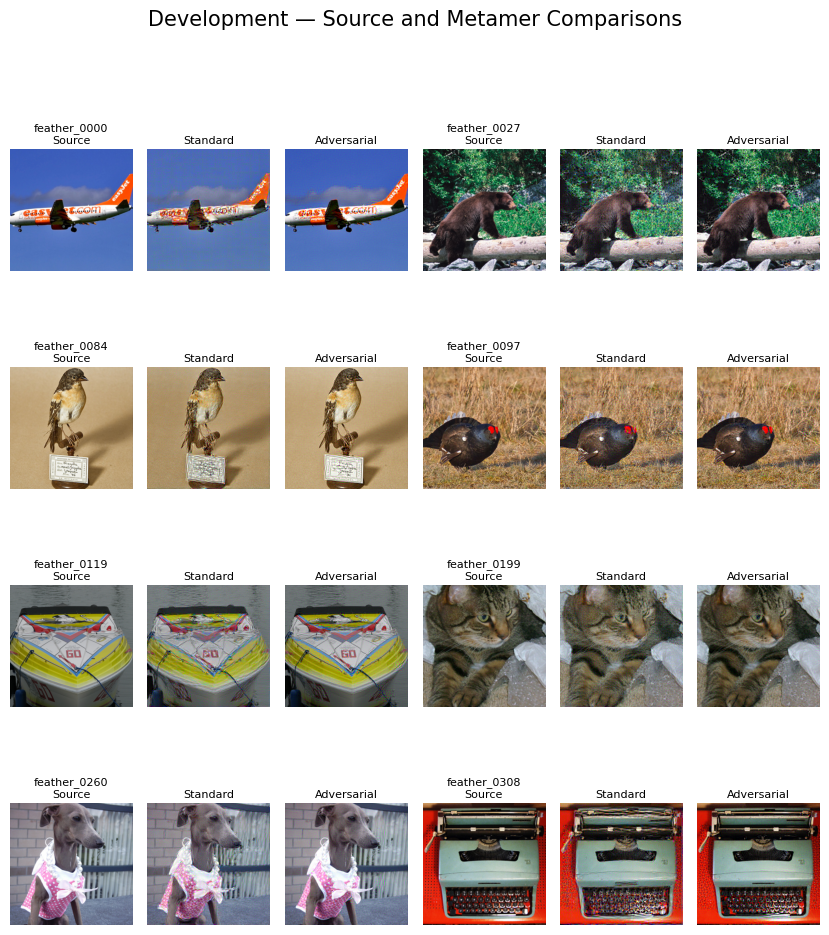

Saved gallery: /content/drive/MyDrive/metamer-sae/stimuli/visualizations/development_gallery.png


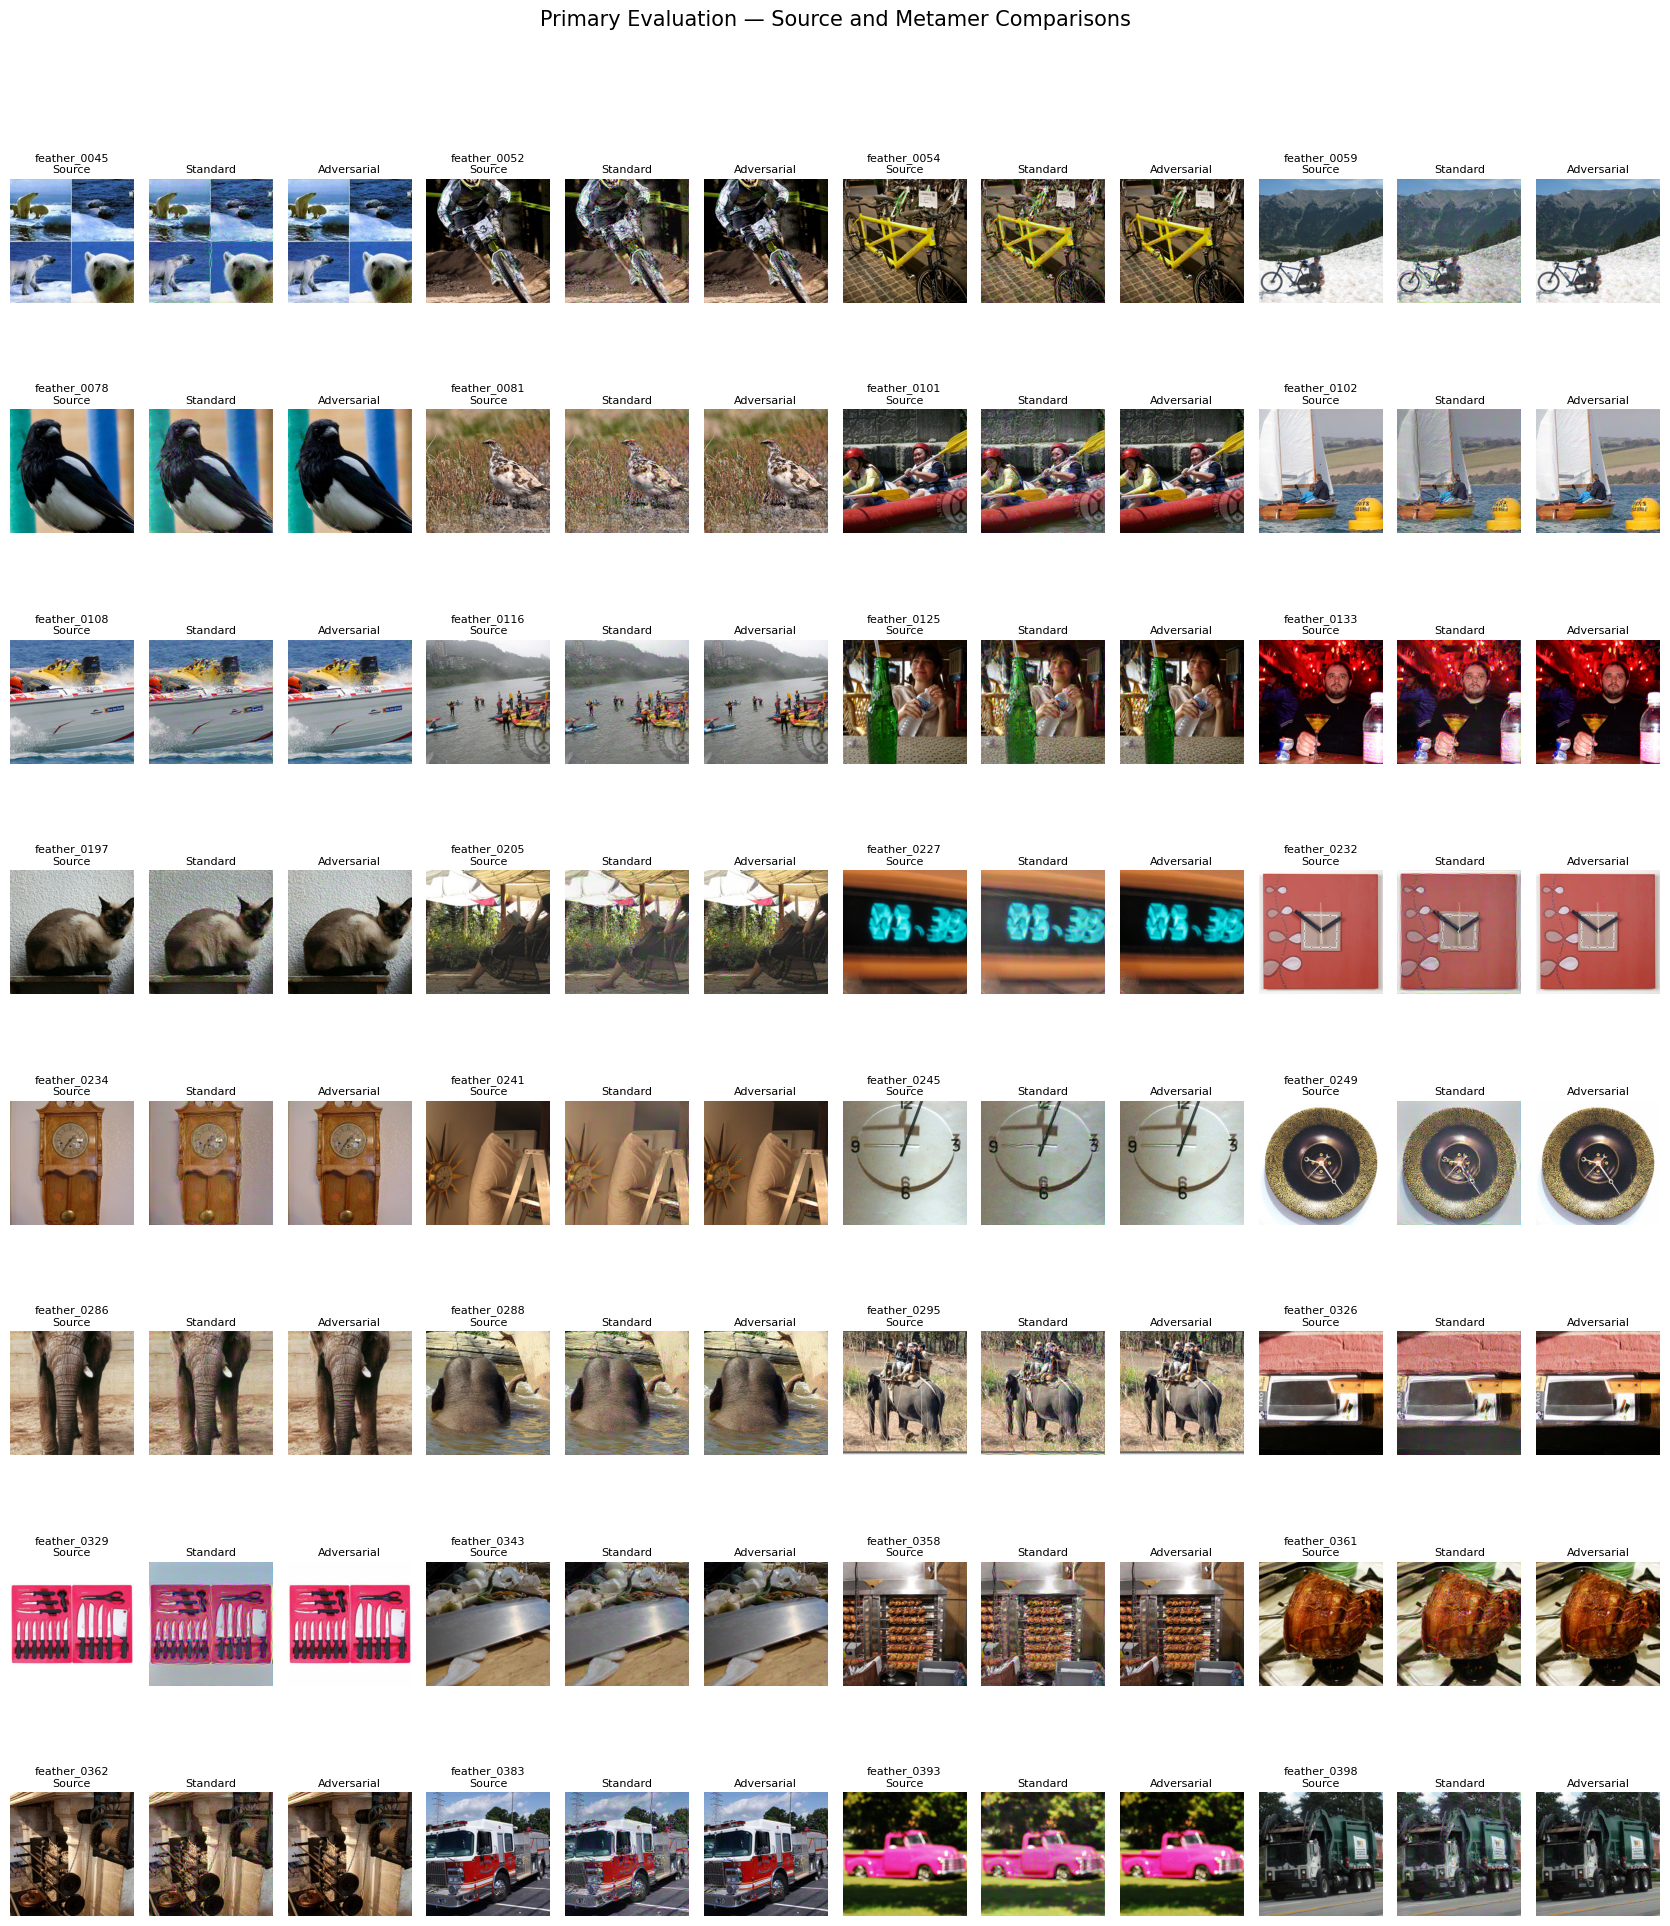

Saved gallery: /content/drive/MyDrive/metamer-sae/stimuli/visualizations/primary_evaluation_gallery.png


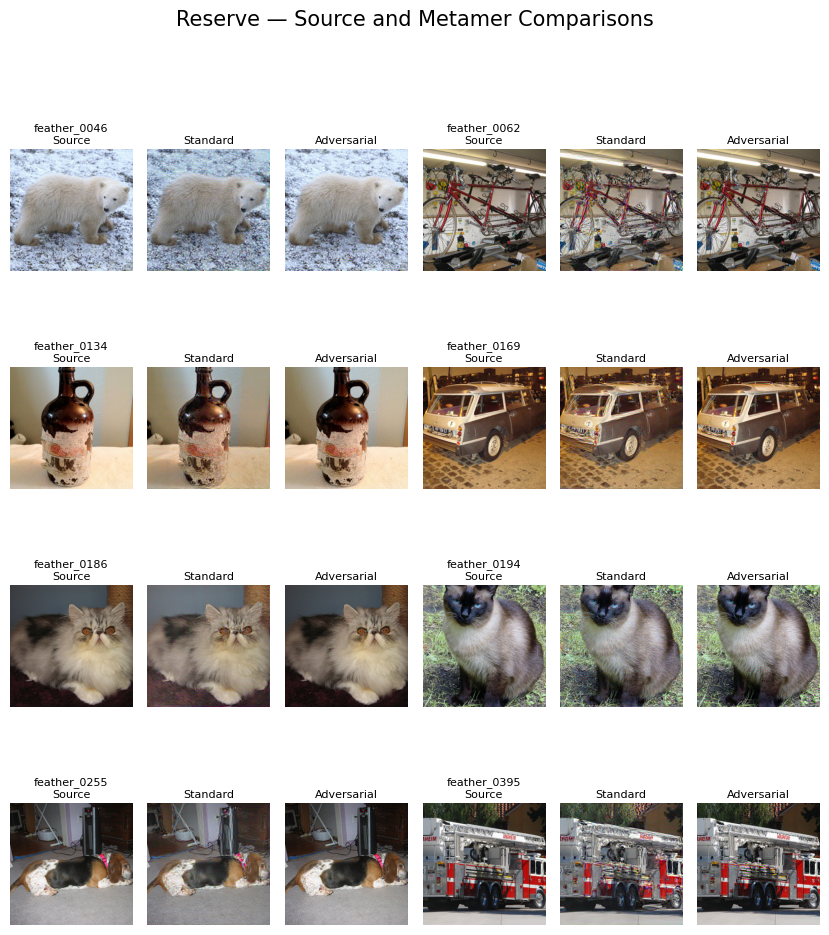

Saved gallery: /content/drive/MyDrive/metamer-sae/stimuli/visualizations/reserve_gallery.png

GALLERY GENERATION SUMMARY
development_gallery.png | Exists: True | Size: 3,038,901 bytes
primary_evaluation_gallery.png | Exists: True | Size: 12,087,577 bytes
reserve_gallery.png | Exists: True | Size: 3,080,273 bytes

SUCCESS: All three galleries were generated.


In [ ]:
import math
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display as ipy_display
from IPython.display import Image as NotebookImage


# ------------------------------------------
# 1. Load and check the final manifest
# ------------------------------------------

manifest_path = MANIFEST_DIR / "stimulus_manifest.csv"

if not manifest_path.exists():
    raise FileNotFoundError(
        "The validated stimulus manifest is missing."
    )

manifest_df = pd.read_csv(manifest_path)

validated_df = manifest_df[
    manifest_df["retrieval_status"] == "validated"
].copy()

if len(validated_df) != 48:
    raise RuntimeError(
        f"Expected 48 validated triplets, "
        f"but found {len(validated_df)}."
    )


# ------------------------------------------
# 2. Confirm that all saved images still exist
# ------------------------------------------

SAVED_PATH_COLUMNS = [
    "source_saved_path",
    "standard_saved_path",
    "adversarial_saved_path"
]

missing_files = []

for _, row in validated_df.iterrows():

    for column in SAVED_PATH_COLUMNS:

        file_path = Path(row[column])

        if not file_path.is_file():
            missing_files.append(str(file_path))

if missing_files:

    raise FileNotFoundError(
        "Some validated image files are missing:\n"
        + "\n".join(missing_files[:20])
    )

print("Manifest check: PASS")
print("Validated triplets:", len(validated_df))
print("All 144 image files exist.")


# ------------------------------------------
# 3. Define gallery-generation function
# ------------------------------------------

def create_triplet_gallery(
    subset,
    output_filename,
    candidates_per_row=2
):

    subset_df = (
        validated_df[
            validated_df["subset"] == subset
        ]
        .sort_values("source_image_id")
        .reset_index(drop=True)
    )

    if subset_df.empty:
        raise ValueError(
            f"No validated images found for subset: {subset}"
        )

    number_of_triplets = len(subset_df)

    number_of_rows = math.ceil(
        number_of_triplets / candidates_per_row
    )

    number_of_columns = candidates_per_row * 3

    fig, axes = plt.subplots(
        number_of_rows,
        number_of_columns,
        figsize=(
            candidates_per_row * 4.2,
            number_of_rows * 2.5
        ),
        squeeze=False
    )

    fig.suptitle(
        f"{subset.replace('_', ' ').title()} "
        f"— Source and Metamer Comparisons",
        fontsize=15,
        y=0.995
    )

    conditions = [
        ("source_saved_path", "Source"),
        ("standard_saved_path", "Standard"),
        ("adversarial_saved_path", "Adversarial")
    ]

    # Hide all axes before filling the available positions.
    for ax in axes.flat:
        ax.axis("off")

    for index, row in subset_df.iterrows():

        gallery_row = index // candidates_per_row

        gallery_group = index % candidates_per_row

        for condition_index, (path_column, label) in enumerate(
            conditions
        ):

            gallery_column = (
                gallery_group * 3 + condition_index
            )

            ax = axes[gallery_row, gallery_column]

            image_path = Path(row[path_column])

            with Image.open(image_path) as image:

                # Convert only for visual display.
                display_image = image.convert("RGB")

                ax.imshow(display_image)

            if condition_index == 0:

                title = (
                    f"{row['stimulus_id']}\n{label}"
                )

            else:

                title = label

            ax.set_title(
                title,
                fontsize=8,
                pad=4
            )

            ax.set_xticks([])
            ax.set_yticks([])

            for spine in ax.spines.values():
                spine.set_visible(False)

    plt.tight_layout(
        rect=[0, 0, 1, 0.97]
    )

    output_path = (
        VISUALIZATION_DIR / output_filename
    )

    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    print("Saved gallery:", output_path)

    return output_path


# ------------------------------------------
# 4. Generate development gallery
# ------------------------------------------

development_gallery = create_triplet_gallery(
    subset="development",
    output_filename="development_gallery.png",
    candidates_per_row=2
)


# ------------------------------------------
# 5. Generate primary evaluation gallery
# ------------------------------------------

primary_gallery = create_triplet_gallery(
    subset="primary_evaluation",
    output_filename="primary_evaluation_gallery.png",
    candidates_per_row=4
)


# ------------------------------------------
# 6. Generate reserve gallery
# ------------------------------------------

reserve_gallery = create_triplet_gallery(
    subset="reserve",
    output_filename="reserve_gallery.png",
    candidates_per_row=2
)


# ------------------------------------------
# 7. Summarize saved galleries
# ------------------------------------------

gallery_paths = [
    development_gallery,
    primary_gallery,
    reserve_gallery
]

print("\n" + "=" * 60)
print("GALLERY GENERATION SUMMARY")
print("=" * 60)

for gallery_path in gallery_paths:

    print(
        gallery_path.name,
        "| Exists:", gallery_path.is_file(),
        "| Size:", f"{gallery_path.stat().st_size:,} bytes"
    )

assert all(path.is_file() for path in gallery_paths)

print("\nSUCCESS: All three galleries were generated.")


# FINAL CHECK — INSPECT SAVED FILE STRUCTURES

In [ ]:
import pandas as pd
from pathlib import Path

STIMULI_DIR = Path(
    "/content/drive/MyDrive/metamer-sae/stimuli"
)

manifest_path = STIMULI_DIR / "manifests" / "stimulus_manifest.csv"
allocation_path = STIMULI_DIR / "manifests" / "stimulus_allocation.csv"
availability_path = STIMULI_DIR / "manifests" / "candidate_availability.csv"
failure_path = STIMULI_DIR / "manifests" / "retrieval_failures.csv"

# Load the saved records
manifest_df = pd.read_csv(manifest_path)
allocation_df = pd.read_csv(allocation_path)
availability_df = pd.read_csv(availability_path)
failures_df = pd.read_csv(failure_path)

# Display the actual structure of each file
for name, df in [
    ("STIMULUS MANIFEST", manifest_df),
    ("STIMULUS ALLOCATION", allocation_df),
    ("CANDIDATE AVAILABILITY", availability_df),
    ("RETRIEVAL FAILURES", failures_df),
]:
    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    display(df.head(3))

print("\nInspection completed.")


STIMULUS MANIFEST
Rows: 48
Columns: ['stimulus_id', 'source_image_id', 'subset', 'generator_standard_experiment', 'generator_standard_model', 'generator_adversarial_experiment', 'generator_adversarial_model', 'generation_layer', 'random_sampling_seed', 'allocation_method', 'complete_url_triplet', 'source_path', 'standard_metamer_path', 'adversarial_metamer_path', 'source_url', 'standard_metamer_url', 'adversarial_metamer_url', 'retrieval_status', 'all_images_downloaded', 'dimensions_match', 'source_width', 'source_height', 'source_mode', 'source_channels', 'source_format', 'source_file_size_bytes', 'source_sha256', 'source_saved_path', 'standard_width', 'standard_height', 'standard_mode', 'standard_channels', 'standard_format', 'standard_file_size_bytes', 'standard_sha256', 'standard_saved_path', 'adversarial_width', 'adversarial_height', 'adversarial_mode', 'adversarial_channels', 'adversarial_format', 'adversarial_file_size_bytes', 'adversarial_sha256', 'adversarial_saved_path', 're

,stimulus_id,source_image_id,subset,generator_standard_experiment,generator_standard_model,generator_adversarial_experiment,generator_adversarial_model,generation_layer,random_sampling_seed,allocation_method,...,standard_saved_path,adversarial_width,adversarial_height,adversarial_mode,adversarial_channels,adversarial_format,adversarial_file_size_bytes,adversarial_sha256,adversarial_saved_path,retrieval_error_count
0,feather_0000,0,development,experiment_1,resnet50,experiment_3,resnet50_l2_3_robust,layer2_fake_relu,42,seeded_random_without_replacement,...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,224,224,RGB,3,PNG,116462,a15e076c20b71893c31c92976f044bfe42b887f044c7be...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,0
1,feather_0027,27,development,experiment_1,resnet50,experiment_3,resnet50_l2_3_robust,layer2_fake_relu,42,seeded_random_without_replacement,...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,224,224,RGB,3,PNG,132450,6d1dbb7c75a7c599372f379e289213586b27f8163ec600...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,0
2,feather_0084,84,development,experiment_1,resnet50,experiment_3,resnet50_l2_3_robust,layer2_fake_relu,42,seeded_random_without_replacement,...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,224,224,RGB,3,PNG,121547,dd7741f5eb96207788c709f3c5d4930a009c88cc9e149c...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,0



STIMULUS ALLOCATION
Rows: 48
Columns: ['stimulus_id', 'source_image_id', 'subset', 'generator_standard_experiment', 'generator_standard_model', 'generator_adversarial_experiment', 'generator_adversarial_model', 'generation_layer', 'random_sampling_seed', 'allocation_method', 'complete_url_triplet', 'source_path', 'standard_metamer_path', 'adversarial_metamer_path', 'source_url', 'standard_metamer_url', 'adversarial_metamer_url']


,stimulus_id,source_image_id,subset,generator_standard_experiment,generator_standard_model,generator_adversarial_experiment,generator_adversarial_model,generation_layer,random_sampling_seed,allocation_method,complete_url_triplet,source_path,standard_metamer_path,adversarial_metamer_path,source_url,standard_metamer_url,adversarial_metamer_url
0,feather_0000,0,development,experiment_1,resnet50,experiment_3,resnet50_l2_3_robust,layer2_fake_relu,42,seeded_random_without_replacement,True,/content/drive/MyDrive/metamer-sae/stimuli/dev...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...
1,feather_0260,260,development,experiment_1,resnet50,experiment_3,resnet50_l2_3_robust,layer2_fake_relu,42,seeded_random_without_replacement,True,/content/drive/MyDrive/metamer-sae/stimuli/dev...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...
2,feather_0308,308,development,experiment_1,resnet50,experiment_3,resnet50_l2_3_robust,layer2_fake_relu,42,seeded_random_without_replacement,True,/content/drive/MyDrive/metamer-sae/stimuli/dev...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...



CANDIDATE AVAILABILITY
Rows: 400
Columns: ['source_image_id', 'source_available', 'standard_available', 'adversarial_available', 'complete_url_triplet', 'source_status', 'standard_status', 'adversarial_status', 'source_url', 'standard_metamer_url', 'adversarial_metamer_url', 'source_probe_method', 'standard_probe_method', 'adversarial_probe_method']


,source_image_id,source_available,standard_available,adversarial_available,complete_url_triplet,source_status,standard_status,adversarial_status,source_url,standard_metamer_url,adversarial_metamer_url,source_probe_method,standard_probe_method,adversarial_probe_method
0,0,True,True,True,True,200,200,200,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,HEAD,HEAD,HEAD
1,1,True,True,True,True,200,200,200,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,HEAD,HEAD,HEAD
2,2,True,True,True,True,200,200,200,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,https://mcdermottlab.mit.edu/mturk_stimuli/ima...,HEAD,HEAD,HEAD



RETRIEVAL FAILURES
Rows: 0
Columns: ['stimulus_id', 'source_image_id', 'subset', 'failed_condition', 'url', 'error']


,stimulus_id,source_image_id,subset,failed_condition,url,error



Inspection completed.


### Final integrity audit — Notebook 02

This final audit independently checks the stimulus allocation, downloaded images, saved manifest and retrieval records.

It verifies that the original 48 selected stimulus triplets have not changed, that each subset has the expected number of triplets, and that every saved image exists, can be decoded, has the recorded dimensions and matches its recorded SHA-256 hash.

The audit does not download, modify, replace or regenerate any stimuli. It is a read-only verification of the completed dataset.

**Expected result:** 48 complete triplets, comprising 8 development, 32 primary evaluation and 8 reserve triplets, with 144 valid image files.

This cell is READ-ONLY.
It does not download, modify, replace or regenerate images.

Checks:
1. Original allocation is unchanged.
2. Subset counts are correct.
3. Allocation and manifest agree.
4. Candidate availability agrees with the selected IDs.
5. All 144 saved images exist and decode.
6. File dimensions, formats and sizes match the manifest.
7. SHA-256 hashes match the saved files.
8. Triplet dimensions match within each stimulus.
9. Experiment, network and layer metadata are consistent.
10. Retrieval failure records are consistent.



In [ ]:
from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image
from IPython.display import display

# ------------------------------------------------------------
# 1. Locate the existing Notebook 02 records
# ------------------------------------------------------------

STIMULI_DIR = Path(
    "/content/drive/MyDrive/metamer-sae/stimuli"
)

MANIFEST_PATH = STIMULI_DIR / "manifests" / "stimulus_manifest.csv"
ALLOCATION_PATH = STIMULI_DIR / "manifests" / "stimulus_allocation.csv"
AVAILABILITY_PATH = STIMULI_DIR / "manifests" / "candidate_availability.csv"
FAILURES_PATH = STIMULI_DIR / "manifests" / "retrieval_failures.csv"

required_files = [
    MANIFEST_PATH,
    ALLOCATION_PATH,
    AVAILABILITY_PATH,
    FAILURES_PATH,
]

missing_records = [str(p) for p in required_files if not p.is_file()]

if missing_records:
    raise FileNotFoundError(
        "The following required audit records are missing:\n"
        + "\n".join(missing_records)
    )

manifest_df = pd.read_csv(MANIFEST_PATH)
allocation_df = pd.read_csv(ALLOCATION_PATH)
availability_df = pd.read_csv(AVAILABILITY_PATH)
failures_df = pd.read_csv(FAILURES_PATH)

# ------------------------------------------------------------
# 2. Define the original expected allocation
#
# These are the IDs selected in Notebook 02.
# We compare against them to detect accidental changes.
# ------------------------------------------------------------

EXPECTED_IDS = {
    "development": {
        0, 260, 308, 84, 199, 119, 97, 27
    },

    "primary_evaluation": {
        116, 101, 133, 125, 232, 362, 227, 326,
        398, 358, 54, 78, 288, 45, 295, 249,
        329, 197, 108, 393, 234, 59, 205, 245,
        102, 343, 52, 241, 286, 81, 383, 361
    },

    "reserve": {
        46, 255, 186, 169, 395, 134, 194, 62
    }
}

EXPECTED_COUNTS = {
    "development": 8,
    "primary_evaluation": 32,
    "reserve": 8
}

EXPECTED_TOTAL_TRIPLETS = 48
EXPECTED_TOTAL_IMAGES = 144

# Store audit results here.
audit_results = []

def record_check(name, passed, details=""):
    """Record and print one audit result."""
    audit_results.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "details": str(details)
    })

# ------------------------------------------------------------
# 3. Check required columns
# ------------------------------------------------------------

required_manifest_columns = [
    "stimulus_id",
    "source_image_id",
    "subset",
    "generator_standard_experiment",
    "generator_standard_model",
    "generator_adversarial_experiment",
    "generator_adversarial_model",
    "generation_layer",
    "complete_url_triplet",
    "retrieval_status",
    "all_images_downloaded",
    "dimensions_match",
    "source_saved_path",
    "standard_saved_path",
    "adversarial_saved_path",
    "source_width",
    "source_height",
    "standard_width",
    "standard_height",
    "adversarial_width",
    "adversarial_height",
    "source_mode",
    "standard_mode",
    "adversarial_mode",
    "source_format",
    "standard_format",
    "adversarial_format",
    "source_file_size_bytes",
    "standard_file_size_bytes",
    "adversarial_file_size_bytes",
    "source_sha256",
    "standard_sha256",
    "adversarial_sha256",
    "retrieval_error_count"
]

required_allocation_columns = [
    "stimulus_id",
    "source_image_id",
    "subset"
]

required_availability_columns = [
    "source_image_id",
    "complete_url_triplet"
]

required_failure_columns = [
    "stimulus_id",
    "source_image_id",
    "failed_condition",
    "error"
]

def missing_columns(df, required):
    return sorted(set(required) - set(df.columns))

column_problems = {
    "manifest": missing_columns(manifest_df, required_manifest_columns),
    "allocation": missing_columns(allocation_df, required_allocation_columns),
    "availability": missing_columns(availability_df, required_availability_columns),
    "failures": missing_columns(failures_df, required_failure_columns)
}

columns_pass = all(not values for values in column_problems.values())

record_check(
    "All required audit columns are present",
    columns_pass,
    column_problems if not columns_pass else "All required columns found."
)

if not columns_pass:
    raise ValueError(
        "The audit cannot continue because required columns are missing. "
        "Review the column names listed above."
    )

# ------------------------------------------------------------
# 4. Normalize the basic data types
# ------------------------------------------------------------

for df in [manifest_df, allocation_df, availability_df]:
    df["source_image_id"] = pd.to_numeric(
        df["source_image_id"], errors="raise"
    ).astype(int)

manifest_df["stimulus_id"] = manifest_df["stimulus_id"].astype(str)
allocation_df["stimulus_id"] = allocation_df["stimulus_id"].astype(str)

for df in [manifest_df, allocation_df]:
    df["subset"] = df["subset"].astype(str).str.strip().str.lower()

# ------------------------------------------------------------
# 5. Check row counts and uniqueness
# ------------------------------------------------------------

record_check(
    "Manifest contains exactly 48 triplets",
    len(manifest_df) == EXPECTED_TOTAL_TRIPLETS,
    f"Manifest rows: {len(manifest_df)}"
)

record_check(
    "Allocation contains exactly 48 records",
    len(allocation_df) == EXPECTED_TOTAL_TRIPLETS,
    f"Allocation rows: {len(allocation_df)}"
)

record_check(
    "Manifest stimulus IDs are unique",
    manifest_df["stimulus_id"].is_unique,
    f"Unique IDs: {manifest_df['stimulus_id'].nunique()}"
)

record_check(
    "Allocation stimulus IDs are unique",
    allocation_df["stimulus_id"].is_unique,
    f"Unique IDs: {allocation_df['stimulus_id'].nunique()}"
)

record_check(
    "Manifest source image IDs are unique",
    manifest_df["source_image_id"].is_unique,
    f"Unique source IDs: {manifest_df['source_image_id'].nunique()}"
)

# ------------------------------------------------------------
# 6. Verify the exact original subset allocation
# ------------------------------------------------------------

allocation_ids = {
    subset: set(
        allocation_df.loc[
            allocation_df["subset"] == subset,
            "source_image_id"
        ]
    )
    for subset in EXPECTED_COUNTS
}

manifest_ids = {
    subset: set(
        manifest_df.loc[
            manifest_df["subset"] == subset,
            "source_image_id"
        ]
    )
    for subset in EXPECTED_COUNTS
}

for subset, expected_ids in EXPECTED_IDS.items():

    actual_allocation_ids = allocation_ids[subset]
    actual_manifest_ids = manifest_ids[subset]

    record_check(
        f"{subset}: allocation count is correct",
        len(actual_allocation_ids) == EXPECTED_COUNTS[subset],
        f"Found {len(actual_allocation_ids)}; expected {EXPECTED_COUNTS[subset]}."
    )

    record_check(
        f"{subset}: original selected IDs are unchanged",
        actual_allocation_ids == expected_ids,
        (
            f"Missing: {sorted(expected_ids - actual_allocation_ids)}; "
            f"Unexpected: {sorted(actual_allocation_ids - expected_ids)}"
        )
    )

    record_check(
        f"{subset}: manifest contains the expected IDs",
        actual_manifest_ids == expected_ids,
        (
            f"Missing: {sorted(expected_ids - actual_manifest_ids)}; "
            f"Unexpected: {sorted(actual_manifest_ids - expected_ids)}"
        )
    )

# Check that no selected ID appears in multiple subsets.
all_allocation_ids = [
    allocation_ids[s] for s in EXPECTED_COUNTS
]

no_subset_overlap = all(
    all_allocation_ids[i].isdisjoint(all_allocation_ids[j])
    for i in range(len(all_allocation_ids))
    for j in range(i + 1, len(all_allocation_ids))
)

record_check(
    "No stimulus appears in multiple allocation subsets",
    no_subset_overlap
)

# ------------------------------------------------------------
# 7. Verify allocation and manifest agree
# ------------------------------------------------------------

allocation_mapping = (
    allocation_df.set_index("stimulus_id")[
        ["source_image_id", "subset"]
    ].sort_index()
)

manifest_mapping = (
    manifest_df.set_index("stimulus_id")[
        ["source_image_id", "subset"]
    ].sort_index()
)

mapping_matches = allocation_mapping.equals(manifest_mapping)

record_check(
    "Allocation and manifest identify the same stimuli and subsets",
    mapping_matches,
    "Compared stimulus IDs, source image IDs and subset assignments."
)

# ------------------------------------------------------------
# 8. Verify candidate availability
# ------------------------------------------------------------

availability_complete = availability_df[
    "complete_url_triplet"
].astype(str).str.lower().isin(["true", "1", "yes"])

complete_candidate_ids = set(
    availability_df.loc[
        availability_complete, "source_image_id"
    ]
)

incomplete_candidate_ids = set(
    availability_df.loc[
        ~availability_complete, "source_image_id"
    ]
)

expected_incomplete_ids = {207, 240, 336}

record_check(
    "Candidate availability contains 400 unique candidates",
    (
        len(availability_df) == 400
        and availability_df["source_image_id"].is_unique
    ),
    f"Rows: {len(availability_df)}; unique IDs: {availability_df['source_image_id'].nunique()}."
)

record_check(
    "Candidate availability contains 397 complete triplets",
    len(complete_candidate_ids) == 397,
    f"Complete candidates: {len(complete_candidate_ids)}."
)

record_check(
    "Previously identified incomplete candidates are unchanged",
    incomplete_candidate_ids == expected_incomplete_ids,
    f"Incomplete candidate IDs: {sorted(incomplete_candidate_ids)}."
)

selected_ids = set(allocation_df["source_image_id"])

record_check(
    "Every allocated stimulus came from the complete candidate pool",
    selected_ids.issubset(complete_candidate_ids),
    f"Allocated IDs checked: {len(selected_ids)}."
)

# ------------------------------------------------------------
# 9. Verify the experiment and generator metadata
# ------------------------------------------------------------

expected_metadata = {
    "generator_standard_experiment": "experiment_1",
    "generator_standard_model": "resnet50",
    "generator_adversarial_experiment": "experiment_3",
    "generator_adversarial_model": "resnet50_l2_3_robust",
    "generation_layer": "layer2_fake_relu"
}

for column, expected_value in expected_metadata.items():

    actual_values = (
        manifest_df[column]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    passed = (
        len(actual_values) == 1
        and actual_values[0] == expected_value
        and manifest_df[column].notna().all()
    )

    record_check(
        f"Metadata: {column}",
        passed,
        f"Observed: {actual_values}; expected: {expected_value}."
    )

# ------------------------------------------------------------
# 10. Check download and retrieval flags
# ------------------------------------------------------------

def truth_series(series):
    return series.astype(str).str.strip().str.lower().isin(
        ["true", "1", "yes"]
    )

record_check(
    "All URL triplets were complete",
    truth_series(manifest_df["complete_url_triplet"]).all(),
    f"Complete: {truth_series(manifest_df['complete_url_triplet']).sum()}/48."
)

record_check(
    "All images were recorded as downloaded",
    truth_series(manifest_df["all_images_downloaded"]).all(),
    f"Downloaded triplets: {truth_series(manifest_df['all_images_downloaded']).sum()}/48."
)

record_check(
    "All triplets were recorded as dimension-matched",
    truth_series(manifest_df["dimensions_match"]).all(),
    f"Dimension-matched triplets: {truth_series(manifest_df['dimensions_match']).sum()}/48."
)

error_counts = pd.to_numeric(
    manifest_df["retrieval_error_count"], errors="coerce"
)

record_check(
    "No retrieval errors are recorded in the manifest",
    error_counts.notna().all() and (error_counts == 0).all(),
    f"Total recorded retrieval errors: {error_counts.sum()}."
)

record_check(
    "Retrieval failure log is empty",
    len(failures_df) == 0,
    f"Failure records: {len(failures_df)}."
)

# ------------------------------------------------------------
# 11. Inspect every saved image
#
# Each stimulus has three files:
# - Source
# - Standard ResNet50 metamer
# - Adversarial ResNet50 metamer
#
# Validate file existence, decoding, dimensions, mode,
# format, file size and SHA-256 hash.
# ------------------------------------------------------------

IMAGE_CONDITIONS = {
    "source": {
        "path": "source_saved_path",
        "width": "source_width",
        "height": "source_height",
        "mode": "source_mode",
        "format": "source_format",
        "size": "source_file_size_bytes",
        "hash": "source_sha256"
    },

    "standard": {
        "path": "standard_saved_path",
        "width": "standard_width",
        "height": "standard_height",
        "mode": "standard_mode",
        "format": "standard_format",
        "size": "standard_file_size_bytes",
        "hash": "standard_sha256"
    },

    "adversarial": {
        "path": "adversarial_saved_path",
        "width": "adversarial_width",
        "height": "adversarial_height",
        "mode": "adversarial_mode",
        "format": "adversarial_format",
        "size": "adversarial_file_size_bytes",
        "hash": "adversarial_sha256"
    }
}

file_results = []
triplet_dimensions = {}
used_paths = []

for _, row in manifest_df.iterrows():

    stimulus_id = row["stimulus_id"]
    triplet_dimensions[stimulus_id] = {}

    for condition, columns in IMAGE_CONDITIONS.items():

        result = {
            "stimulus_id": stimulus_id,
            "condition": condition,
            "path": "",
            "exists": False,
            "decodes": False,
            "size_matches": False,
            "hash_matches": False,
            "dimensions_match": False,
            "mode_matches": False,
            "format_matches": False,
            "actual_width": None,
            "actual_height": None,
            "error": ""
        }

        try:
            raw_path = row[columns["path"]]

            if pd.isna(raw_path) or not str(raw_path).strip():
                raise ValueError("Saved path is empty.")

            image_path = Path(str(raw_path)).expanduser()
            result["path"] = str(image_path)
            result["exists"] = image_path.is_file()

            if not result["exists"]:
                raise FileNotFoundError(
                    f"Image file does not exist: {image_path}"
                )

            used_paths.append(str(image_path.resolve()))

            # Check file size.
            actual_size = image_path.stat().st_size
            expected_size = int(row[columns["size"]])

            result["size_matches"] = actual_size == expected_size

            # Calculate actual SHA-256 hash.
            actual_hash = hashlib.sha256(
                image_path.read_bytes()
            ).hexdigest()

            expected_hash = str(row[columns["hash"]]).strip().lower()

            result["hash_matches"] = (
                actual_hash.lower() == expected_hash
            )

            # Verify image integrity and decode it.
            with Image.open(image_path) as img:
                img.verify()

            with Image.open(image_path) as img:
                actual_width, actual_height = img.size
                actual_mode = img.mode
                actual_format = img.format

                result["decodes"] = True
                result["actual_width"] = actual_width
                result["actual_height"] = actual_height

                # Compare dimensions with recorded manifest values.
                expected_width = int(row[columns["width"]])
                expected_height = int(row[columns["height"]])

                result["dimensions_match"] = (
                    actual_width == expected_width
                    and actual_height == expected_height
                )

                # Compare image mode and format.
                expected_mode = str(row[columns["mode"]]).strip()
                expected_format = str(row[columns["format"]]).strip()

                result["mode_matches"] = (
                    actual_mode == expected_mode
                )

                result["format_matches"] = (
                    actual_format.upper() == expected_format.upper()
                )

                triplet_dimensions[stimulus_id][condition] = (
                    actual_width, actual_height
                )

        except Exception as exc:
            result["error"] = str(exc)

        file_results.append(result)

file_audit_df = pd.DataFrame(file_results)

# ------------------------------------------------------------
# 12. Summarize the 144 individual image checks
# ------------------------------------------------------------

record_check(
    "All 144 expected image paths exist",
    len(file_audit_df) == EXPECTED_TOTAL_IMAGES
    and file_audit_df["exists"].all(),
    f"Existing files: {file_audit_df['exists'].sum()}/{EXPECTED_TOTAL_IMAGES}."
)

record_check(
    "All 144 images decode successfully",
    len(file_audit_df) == EXPECTED_TOTAL_IMAGES
    and file_audit_df["decodes"].all(),
    f"Successfully decoded: {file_audit_df['decodes'].sum()}/{EXPECTED_TOTAL_IMAGES}."
)

record_check(
    "All recorded file sizes match disk",
    len(file_audit_df) == EXPECTED_TOTAL_IMAGES
    and file_audit_df["size_matches"].all(),
    f"Matching file sizes: {file_audit_df['size_matches'].sum()}/{EXPECTED_TOTAL_IMAGES}."
)

record_check(
    "All SHA-256 hashes match",
    len(file_audit_df) == EXPECTED_TOTAL_IMAGES
    and file_audit_df["hash_matches"].all(),
    f"Matching hashes: {file_audit_df['hash_matches'].sum()}/{EXPECTED_TOTAL_IMAGES}."
)

record_check(
    "All recorded dimensions match the actual images",
    len(file_audit_df) == EXPECTED_TOTAL_IMAGES
    and file_audit_df["dimensions_match"].all(),
    f"Matching dimensions: {file_audit_df['dimensions_match'].sum()}/{EXPECTED_TOTAL_IMAGES}."
)

record_check(
    "All recorded image modes match",
    len(file_audit_df) == EXPECTED_TOTAL_IMAGES
    and file_audit_df["mode_matches"].all(),
    f"Matching modes: {file_audit_df['mode_matches'].sum()}/{EXPECTED_TOTAL_IMAGES}."
)

record_check(
    "All recorded image formats match",
    len(file_audit_df) == EXPECTED_TOTAL_IMAGES
    and file_audit_df["format_matches"].all(),
    f"Matching formats: {file_audit_df['format_matches'].sum()}/{EXPECTED_TOTAL_IMAGES}."
)

# ------------------------------------------------------------
# 13. Check that the three images in each triplet have
#     matching actual dimensions.
# ------------------------------------------------------------

triplet_dimension_results = []

for stimulus_id, dimensions in triplet_dimensions.items():

    all_three_present = len(dimensions) == 3

    dimensions_match = (
        all_three_present
        and len(set(dimensions.values())) == 1
    )

    triplet_dimension_results.append({
        "stimulus_id": stimulus_id,
        "all_three_images_decoded": all_three_present,
        "dimensions_match": dimensions_match,
        "dimensions": dimensions
    })

triplet_dimension_df = pd.DataFrame(triplet_dimension_results)

record_check(
    "All 48 triplets have three decodable images with matching dimensions",
    (
        len(triplet_dimension_df) == EXPECTED_TOTAL_TRIPLETS
        and triplet_dimension_df["all_three_images_decoded"].all()
        and triplet_dimension_df["dimensions_match"].all()
    ),
    (
        "Matching triplets: "
        f"{triplet_dimension_df['dimensions_match'].sum()}/48."
    )
)

# ------------------------------------------------------------
# 14. Check that all 144 paths are distinct
# ------------------------------------------------------------

record_check(
    "All 144 image paths are unique",
    (
        len(used_paths) == EXPECTED_TOTAL_IMAGES
        and len(set(used_paths)) == EXPECTED_TOTAL_IMAGES
    ),
    f"Unique paths: {len(set(used_paths))}/{EXPECTED_TOTAL_IMAGES}."
)

# ------------------------------------------------------------
# 15. Determine the number of fully valid triplets
#
# A triplet is valid only when all three files pass every
# individual file check and their actual dimensions agree.
# ------------------------------------------------------------

file_pass_columns = [
    "exists",
    "decodes",
    "size_matches",
    "hash_matches",
    "dimensions_match",
    "mode_matches",
    "format_matches"
]

file_audit_df["file_fully_valid"] = (
    file_audit_df[file_pass_columns].all(axis=1)
)

valid_files_per_stimulus = (
    file_audit_df.groupby("stimulus_id")["file_fully_valid"]
    .sum()
)

matching_dimension_ids = set(
    triplet_dimension_df.loc[
        triplet_dimension_df["dimensions_match"],
        "stimulus_id"
    ]
)

valid_triplet_ids = {
    stimulus_id
    for stimulus_id, valid_file_count in valid_files_per_stimulus.items()
    if valid_file_count == 3
    and stimulus_id in matching_dimension_ids
}

manifest_df["audit_valid_triplet"] = (
    manifest_df["stimulus_id"].isin(valid_triplet_ids)
)

record_check(
    "All 48 triplets pass the complete file-level audit",
    len(valid_triplet_ids) == EXPECTED_TOTAL_TRIPLETS,
    f"Fully valid triplets: {len(valid_triplet_ids)}/48."
)

primary_valid_count = manifest_df.loc[
    manifest_df["subset"] == "primary_evaluation",
    "audit_valid_triplet"
].sum()

record_check(
    "Primary evaluation contains exactly 32 fully valid triplets",
    primary_valid_count == 32,
    f"Valid primary evaluation triplets: {primary_valid_count}/32."
)

# ------------------------------------------------------------
# 16. Display final audit results
# ------------------------------------------------------------

audit_df = pd.DataFrame(audit_results)

print("\n" + "=" * 75)
print("METAMER-SAE — NOTEBOOK 02 FINAL INTEGRITY AUDIT")
print("=" * 75)

display(audit_df)

# Display file-level problems only when they exist.
problem_files = file_audit_df[
    ~file_audit_df[file_pass_columns].all(axis=1)
]

if not problem_files.empty:
    print("\nFILE-LEVEL PROBLEMS:")
    display(problem_files)

# Display failed triplets, if any.
failed_triplets = manifest_df[
    ~manifest_df["audit_valid_triplet"]
][["stimulus_id", "source_image_id", "subset"]]

if not failed_triplets.empty:
    print("\nTRIPLETS THAT DID NOT PASS:")
    display(failed_triplets)

# Display a concise subset summary.
subset_summary = (
    manifest_df.groupby("subset")
    .agg(
        allocated_triplets=("stimulus_id", "count"),
        fully_valid_triplets=("audit_valid_triplet", "sum")
    )
    .reindex(["development", "primary_evaluation", "reserve"])
)

print("\nSUBSET SUMMARY:")
display(subset_summary)

# Display retrieval status values for reference.
print("\nRECORDED RETRIEVAL STATUS:")
display(manifest_df["retrieval_status"].value_counts(dropna=False))

# ------------------------------------------------------------
# 17. Final PASS / FAIL decision
# ------------------------------------------------------------

all_passed = (audit_df["status"] == "PASS").all()

print("\n" + "=" * 75)

if all_passed:
    print("FINAL RESULT: ALL AUTOMATED INTEGRITY CHECKS PASSED")
    print()
    print("48 / 48 complete stimulus triplets verified.")
    print("8 development triplets.")
    print("32 primary evaluation triplets.")
    print("8 reserve triplets.")
    print("144 / 144 image files verified.")
    print("All recorded SHA-256 hashes match.")
    print("All recorded dimensions and file metadata match.")
    print()
    print("Notebook 02 has passed its automated integrity audit.")
    print("Visual gallery inspection is still required before closure.")
else:
    failed_count = (audit_df["status"] == "FAIL").sum()

    print(f"FINAL RESULT: {failed_count} AUDIT CHECK(S) FAILED")
    print()
    print("Do not mark Notebook 02 as complete yet.")
    print("Review the failed checks and any file-level problems above.")

print("=" * 75)



METAMER-SAE — NOTEBOOK 02 FINAL INTEGRITY AUDIT


,check,status,details
0,All required audit columns are present,PASS,All required columns found.
1,Manifest contains exactly 48 triplets,PASS,Manifest rows: 48
2,Allocation contains exactly 48 records,PASS,Allocation rows: 48
3,Manifest stimulus IDs are unique,PASS,Unique IDs: 48
4,Allocation stimulus IDs are unique,PASS,Unique IDs: 48
5,Manifest source image IDs are unique,PASS,Unique source IDs: 48
6,development: allocation count is correct,PASS,Found 8; expected 8.
7,development: original selected IDs are unchanged,PASS,Missing: []; Unexpected: []
8,development: manifest contains the expected IDs,PASS,Missing: []; Unexpected: []
9,primary_evaluation: allocation count is correct,PASS,Found 32; expected 32.



SUBSET SUMMARY:


,allocated_triplets,fully_valid_triplets
subset,,
development,8,8
primary_evaluation,32,32
reserve,8,8



RECORDED RETRIEVAL STATUS:


,count
retrieval_status,
validated,48



FINAL RESULT: ALL AUTOMATED INTEGRITY CHECKS PASSED

48 / 48 complete stimulus triplets verified.
8 development triplets.
32 primary evaluation triplets.
8 reserve triplets.
144 / 144 image files verified.
All recorded SHA-256 hashes match.
All recorded dimensions and file metadata match.

Notebook 02 has passed its automated integrity audit.
Visual gallery inspection is still required before closure.
